# Analysis

Python is the default kernel. An R kernel is fine if that is the language you can explain. `CHECKLIST.md` is the list that counts. The ticks on the lab page do not.

The held-out score, in the units of the decision, is computed in this notebook. The reason slide in `presentation.qmd` has to agree with it. The risk slide is the risk of the action, not this score.


## Setup

I import the packages and my own functions from `house_model.py`. No random seed is needed: the split is by date and nothing is drawn at random.

The notebook reads one file, `data/fairfax_selected.csv`. `load_sales` computes its SHA-256 and stops with a message if it differs from the one recorded in `data/README.md`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import house_model as hm

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

sales = hm.load_sales()
print("SHA-256 matches:", hm.EXPECTED_SHA256)
print(f"{len(sales):,} sales, from {sales['sale_date'].min().date()} to {sales['sale_date'].max().date()}")

SHA-256 matches: 822756ecb502bc589e8ec9b02c3426a2f01861bfe04e70818876e59bffc6c3d5
70,306 sales, from 2020-01-02 to 2026-09-15


## Question

For a house listed for sale near Reston, Virginia, what is the most I should offer?

The quantity I estimate is the sale price of a house, in dollars, for single family houses and townhouses in Fairfax County that sell after 2026-02-28. For each house I give a low, a middle, and a high estimate. My offer is the low estimate.

![Layer diagram](fig/layers.png)

## Data

The source is the Fairfax County open data site, tables from the Department of Tax Administration: recorded sales joined to house details by parcel ID. One row is one recorded sale of one house.

The county does not clearly allow republishing, so there is no `data` release. `data/README.md` gives the three commands that rebuild the file, and `decisions.md` lists the filters.

I split the sales by date in the first cell below, before any plot, so that nothing in this section can show the test months. The Split section explains the split.

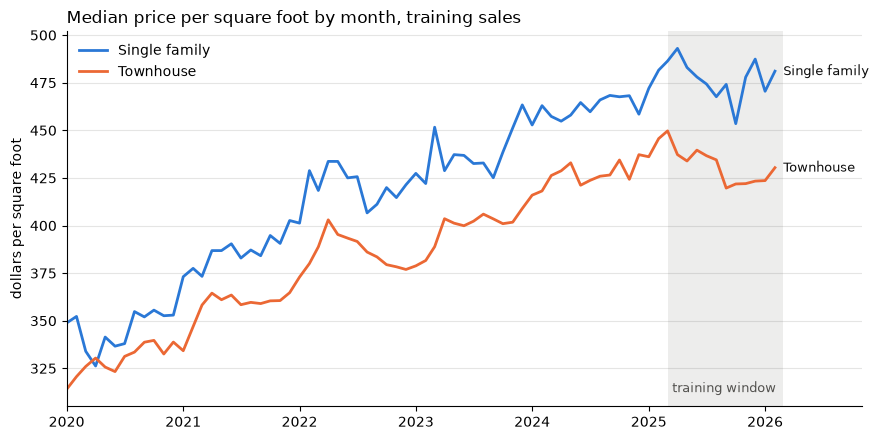

In [2]:
train, test = hm.split_by_date(sales, hm.CUTOFF)
window = hm.training_window(train, hm.WINDOW_START)

# Raw-data plot: median price per square foot by month, training sales only.
monthly = (train.groupby([train["sale_date"].dt.to_period("M").dt.to_timestamp(), "property_type"])
           ["price_per_sqft"].median().unstack())
labels = {"single_family": "Single family", "townhouse": "Townhouse"}
colors = {"single_family": "#2a78d6", "townhouse": "#eb6834"}

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.axvspan(window["sale_date"].min(), window["sale_date"].max(), color="#52514e", alpha=0.10, lw=0)
ax.text(window["sale_date"].min(), 0.03, " training window", transform=ax.get_xaxis_transform(),
        color="#52514e", fontsize=9, va="bottom")
for kind in ["single_family", "townhouse"]:
    ax.plot(monthly.index, monthly[kind], color=colors[kind], lw=2, label=labels[kind])
    ax.annotate(labels[kind], (monthly.index[-1], monthly[kind].iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=9, color="#0b0b0b")
ax.set_title("Median price per square foot by month, training sales", loc="left")
ax.set_ylabel("dollars per square foot")
ax.set_xlim(monthly.index[0], monthly.index[-1] + pd.DateOffset(months=9))
ax.grid(axis="y", color="#52514e", alpha=0.15)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig("fig/price_per_sqft_by_month.png", dpi=150)
plt.show()

The plot shows the raw price per square foot, before any model. Prices rose from 2020 to early 2025 and have moved little since. The shaded months are the training window. Single family houses cost more per square foot than townhouses.

The table below describes the sales in the training window. For each feature it gives the lower quartile, the median, and the upper quartile. An empty half bath field counts as zero.

In [3]:
features = {"price": "price ($)", "living_area_sqft": "living area (sq ft)", "age": "age at sale (years)",
            "lot_sqft": "lot size (sq ft)", "bedrooms": "bedrooms", "full_baths": "full baths",
            "half_baths": "half baths"}
described = window.assign(half_baths=window["half_baths"].fillna(0))
parts = {}
for kind, group in described.groupby("property_type"):
    quartiles = group[list(features)].quantile([0.25, 0.50, 0.75]).T
    quartiles.columns = ["25%", "median", "75%"]
    parts[f"{labels[kind]} ({len(group):,} sales)"] = quartiles
summary = pd.concat(parts, axis=1).rename(index=features)
print("Sales with no lot size:", window["lot_sqft"].isna().groupby(window["property_type"]).sum().to_dict())
summary.round(0).astype(int)

Sales with no lot size: {'single_family': 1, 'townhouse': 152}


Single family (5,347 sales)                  Townhouse (3,111 sales)                
                                            25%  median      75%                     25%  median     75%
price ($)                                812000  980500  1350000                  570000  653000  775000
living area (sq ft)                        1536    2200     3121                    1320    1554    1800
age at sale (years)                          35      47       61                      27      38      46
lot size (sq ft)                          10329   12536    20010                    1470    1745    2263
bedrooms                                      4       4        5                       3       3       3
full baths                                    2       3        4                       2       2       3
half baths                                    0       1        1                       1       1       2

### Why I model the log of the price

I fit two very simple models on all training sales. One predicts the price in dollars from the living area. The other predicts the log of the price from the log of the living area. The table shows the spread of their errors (standard deviation) for the smallest fifth of houses up to the largest fifth.

In dollars, the spread for the largest houses is several times the spread for the smallest. On the log scale it stays about the same, so one spread can serve all houses, and that is why I model the log of the price.

In [4]:
spread = hm.error_spread_by_size(train)
spread.round({"error_spread_dollars": 0, "error_spread_log": 3})

,sales,error_spread_dollars,error_spread_log
living_area_sqft,,,
"(399.999, 1336.0]",12935,142264.0,0.247
"(1336.0, 1622.0]",12882,156680.0,0.233
"(1622.0, 2019.0]",12879,174286.0,0.216
"(2019.0, 2794.2]",12896,216370.0,0.216
"(2794.2, 14354.0]",12898,465778.0,0.282


## Split

I split by time, not at random. I will use the model on houses that sell after my data ends, so the test sales must be later than the training sales. A random split would let the model see sales from the same months it is tested on.

Sales before 2026-03-01 are training sales. Sales from 2026-03-01 on are test sales. Both methods learn only from the training window, the last 12 months before the cutoff. Earlier training sales are used only for the plot and the tables above. The test sales are scored once.

In [5]:
def describe(part):
    return {"sales": len(part), "first sale": part["sale_date"].min().date(), "last sale": part["sale_date"].max().date(),
            "single family": int((part["property_type"] == "single_family").sum()),
            "townhouse": int((part["property_type"] == "townhouse").sum())}

pd.DataFrame({"all training sales": describe(train),
              "training window (both methods learn here)": describe(window),
              "test sales": describe(test)}).T

,sales,first sale,last sale,single family,townhouse
all training sales,64490,2020-01-02,2026-02-27,38847,25643
training window (both methods learn here),8458,2025-03-03,2026-02-27,5347,3111
test sales,5816,2026-03-02,2026-09-15,3828,1988


## Baseline

The baseline is a common rule of thumb:

fair price = (median price per square foot of the zip code) x (living area of the house)

The median comes from the training window, with houses and townhouses together. A zip code with fewer than 30 sales in the window uses the county-wide median.

In [6]:
medians = hm.fit_zip_medians(window)
nearby = ["20190", "20191", "20194", "20170", "20171"]   # Reston and Herndon
print(f"Zip codes with their own median: {len(medians['zip_median'])} of {len(medians['zip_sales'])}")
print(f"County-wide median: ${medians['county_median']:.2f} per square foot")
pd.DataFrame({"median $ per sq ft": medians["zip_median"].reindex(nearby).round(2),
              "window sales": medians["zip_sales"].reindex(nearby)})

Zip codes with their own median: 41 of 48
County-wide median: $452.51 per square foot


,median $ per sq ft,window sales
zip,,
20190,465.71,123
20191,444.24,279
20194,473.32,124
20170,403.86,360
20171,412.35,336


### Low and high estimates

A fair price is a middle estimate. For an offer I need a low estimate. I get it from how wrong the method was on training sales.

For each sale in the training window I divide the real price by the fair price. A ratio of 0.80 means the house sold for 80% of the fair price. I sort the ratios and read off cut points, separately for single family houses and townhouses. The 10% cut point is the ratio that 10% of those sales fall below.

The estimate at a level is the fair price times the cut point. If the fair price of a townhouse is $750,000 and the 10% cut point for townhouses is 0.83, the 10% low estimate is 750,000 x 0.83 = $622,500. About one such house in ten should sell for less than that. The 10% and 90% estimates are the ends of the 80% range.

In [7]:
baseline_window = hm.baseline_fair_price(window, medians)
baseline_cuts = hm.fit_cut_points(window["price"], baseline_window, window["property_type"])
baseline_cuts.round(4)

,0.05,0.10,0.25,0.50,0.75,0.90
property_type,,,,,,
single_family,0.7350,0.7931,0.8884,1.0200,1.2012,1.4007
townhouse,0.7785,0.8248,0.8966,0.9808,1.0693,1.1564


### Baseline on the test sales

I score the offers against the recorded sale prices. Overpaid means my offer is above the sale price. Close means my offer is from 95% to 100% of the sale price.

In [8]:
baseline_test = hm.baseline_fair_price(test, medians)
baseline_miss = hm.typical_miss(baseline_test, test["price"])
print(f"Typical miss of the fair price: ${baseline_miss['median_miss_dollars']:,.0f}, "
      f"or {baseline_miss['median_miss_percent']:.1f}% of the sale price (median)")
baseline_scores = hm.score_method(test, baseline_test, baseline_cuts)
hm.readable_scores(baseline_scores)

Typical miss of the fair price: $111,752, or 12.6% of the sale price (median)


,overpaid,"avg $ over, when overpaid","avg $ over, all offers",close offers,"median offer, % of price"
comfort_level,,,,,
5%,"251 of 5,816 (4.3%)","109,268","4,716","199 of 5,816 (3.4%)",74.0%
10%,"541 of 5,816 (9.3%)","110,308","10,261","331 of 5,816 (5.7%)",79.1%
25%,"1,308 of 5,816 (22.5%)","130,582","29,367","538 of 5,816 (9.3%)",87.4%


## Model

The model is a linear regression on the log of the sale price. For one house:

log(price) = b0
 + b_area x log(living area in square feet)
 + b_town x (1 if townhouse, 0 if single family)
 + b_age x (sale year minus year built)
 + b_bed x (bedrooms)
 + b_full x (full baths)
 + b_half x (half baths)
 + b_lot x log(lot size in square feet)
 + b_nolot x (1 if no lot size is recorded, else 0)
 + b_zip (one number for the house's zip code)
 + error

The fair price is e to the power of that sum, without the error term.

What each parameter means:

- b0 is the starting level: the log price of a house with all other terms at zero, in the reference zip code.
- b_area: if the living area is 10% larger, the price is multiplied by 1.10 to the power b_area.
- b_town, b_bed, b_full, b_half: one more unit multiplies the price by e to the power of the coefficient. For small coefficients that is about the coefficient as a percent.
- b_age: the same, for each year of age.
- b_lot: like b_area, for the lot.
- b_nolot: townhouses in condominium developments have no lot of their own. For them log(lot size) is set to 0 and this term carries their level.
- b_zip: how much more or less a like house costs in that zip code than in the reference zip code, the one with the most sales. Zip codes with fewer than 30 sales in the window share one number.
- error: everything the features do not explain. Its spread is what the low and high estimates are built from.

There is no term for the sale date, and the county's grade and condition ratings are not used. `decisions.md` gives the reasons.

Assumptions: the effects add up on the log scale. Prices are flat inside the training window and stay at that level for the test months. The errors of future sales look like the errors of the training sales of the same type. The assumption I trust least is the flat price level, because the model has no way to follow the market if it moves.

In [9]:
model = hm.fit_model(window)
fit = model["result"]
print(f"Training sales: {int(fit.nobs):,}")
print(f"Parameters: {len(fit.params)} (intercept, 8 features, {len(fit.params) - 9} zip codes)")
print(f"R-squared: {fit.rsquared:.4f}")
print(f"Spread of the errors on the log scale (residual standard deviation): {np.sqrt(fit.mse_resid):.4f}")
print("percent_effect: for log_living_area and log_lot, the effect of 10% more. For the others, the effect of one more unit.")
hm.coefficient_table(model).round({"coefficient": 5, "standard_error": 5, "percent_effect": 2})

Training sales: 8,458
Parameters: 50 (intercept, 8 features, 41 zip codes)
R-squared: 0.9251
Spread of the errors on the log scale (residual standard deviation): 0.1156
percent_effect: for log_living_area and log_lot, the effect of 10% more. For the others, the effect of one more unit.


,coefficient,standard_error,percent_effect
intercept,10.37925,0.04435,NaN
log_living_area,0.32730,0.00627,3.17
townhouse,-0.12043,0.00615,-11.35
age,-0.00375,0.00010,-0.37
bedrooms,0.00921,0.00218,0.92
full_baths,0.05899,0.00215,6.08
half_baths,0.02946,0.00280,2.99
log_lot,0.08763,0.00267,0.84
lot_missing,0.47062,0.02253,60.10


In [10]:
print(f"Zip code effects against the reference zip code {model['zips'][0]}:")
hm.zip_effect_table(model, nearby + [model["zips"][0]]).round({"coefficient": 4, "standard_error": 4, "percent_vs_reference": 1})

Zip code effects against the reference zip code 22015:


,coefficient,standard_error,percent_vs_reference
zip,,,
20190,0.1775,0.0122,19.4
20191,0.0695,0.0092,7.2
20194,0.0903,0.0120,9.4
20170,-0.0969,0.0086,-9.2
20171,-0.0181,0.0088,-1.8
22015,0.0000,NaN,0.0


### Cut points for the model

The model gets its low and high estimates the same way as the baseline, from its own ratios of real price to fair price in the training window.

In [11]:
model_window = hm.model_fair_price(window, model)
model_cuts = hm.fit_cut_points(window["price"], model_window, window["property_type"])
model_cuts.round(4)

,0.05,0.10,0.25,0.50,0.75,0.90
property_type,,,,,,
single_family,0.8277,0.8682,0.9282,0.9966,1.0734,1.1519
townhouse,0.8654,0.8986,0.9435,0.9987,1.0538,1.1143


### One house, term by term

This is a real single family house from the training window in Reston. I took the first one by sale ID, so it is not picked to look good. It is a training sale, so the model has seen its price.

In [12]:
in_reston = window["zip"].isin(["20190", "20191", "20194"]) & (window["property_type"] == "single_family")
example = window[in_reston].sort_values("sale_id").iloc[[0]]
house = example.iloc[0]
print(f"{house['address']}, {house['city']} {house['zip']}, sold {house['sale_date'].date()}")
print(f"living area {house['living_area_sqft']:,.0f} sq ft, built {int(house['year_built'])}, "
      f"{int(house['bedrooms'])} bedrooms, {int(house['full_baths'])} full baths, "
      f"half baths {0 if pd.isna(house['half_baths']) else int(house['half_baths'])}, lot {house['lot_sqft']:,.0f} sq ft")
terms = hm.worked_example(example, model)
terms.round(5)

10914 HUNT CLUB RD, RESTON 20190, sold 2025-03-18
living area 1,953 sq ft, built 1970, 4 bedrooms, 2 full baths, half baths 1, lot 14,059 sq ft


,value,coefficient,value_x_coefficient
intercept,1.00000,10.37925,10.37925
log_living_area,7.57712,0.32730,2.48001
age,55.00000,-0.00375,-0.20639
bedrooms,4.00000,0.00921,0.03683
full_baths,2.00000,0.05899,0.11797
half_baths,1.00000,0.02946,0.02946
log_lot,9.55102,0.08763,0.83692
zip_20190,1.00000,0.17752,0.17752


In [13]:
log_estimate = terms["value_x_coefficient"].sum()
fair = np.exp(log_estimate)
kind = house["property_type"]
print(f"Sum of the last column (log estimate): {log_estimate:.5f}")
print(f"Fair price = e^{log_estimate:.5f} = ${fair:,.0f}")
for level in [0.05, 0.10, 0.25, 0.90]:
    cut = model_cuts.loc[kind, level]
    print(f"  {level:.0%} estimate = {fair:,.0f} x {cut:.4f} = ${fair * cut:,.0f}")
rule = hm.baseline_fair_price(example, medians).iloc[0]
print(f"Rule of thumb: {rule / house['living_area_sqft']:.2f} x {house['living_area_sqft']:,.0f} = ${rule:,.0f}, "
      f"10% estimate ${rule * baseline_cuts.loc[kind, 0.10]:,.0f}")
print(f"Real sale price: ${house['price']:,.0f}")

Sum of the last column (log estimate): 13.85158
Fair price = e^13.85158 = $1,036,725
  5% estimate = 1,036,725 x 0.8277 = $858,068
  10% estimate = 1,036,725 x 0.8682 = $900,112
  25% estimate = 1,036,725 x 0.9282 = $962,286
  90% estimate = 1,036,725 x 1.1519 = $1,194,224
Rule of thumb: 465.71 x 1,953 = $909,540, 10% estimate $721,346
Real sale price: $950,000


### Model on the test sales

The same test sales as the baseline, scored the same way.

In [14]:
model_test = hm.model_fair_price(test, model)
model_miss = hm.typical_miss(model_test, test["price"])
print(f"Typical miss of the fair price: ${model_miss['median_miss_dollars']:,.0f}, "
      f"or {model_miss['median_miss_percent']:.1f}% of the sale price (median)")
model_scores = hm.score_method(test, model_test, model_cuts)
hm.readable_scores(model_scores)

Typical miss of the fair price: $60,213, or 6.9% of the sale price (median)


,overpaid,"avg $ over, when overpaid","avg $ over, all offers",close offers,"median offer, % of price"
comfort_level,,,,,
5%,"249 of 5,816 (4.3%)","54,964","2,353","301 of 5,816 (5.2%)",82.5%
10%,"485 of 5,816 (8.3%)","60,822","5,072","509 of 5,816 (8.8%)",86.1%
25%,"1,129 of 5,816 (19.4%)","67,293","13,063","915 of 5,816 (15.7%)",91.5%


### Baseline and model side by side

Each row is one comfort level and one method, on the same test sales. The offer is the low estimate at that level. My comfort level is 10%.

In [15]:
side_by_side = pd.concat({"rule of thumb": hm.readable_scores(baseline_scores),
                          "model": hm.readable_scores(model_scores)}, names=["method"])
side_by_side = side_by_side.swaplevel().sort_index(key=lambda idx: idx.map({"5%": 0, "10%": 1, "25%": 2, "rule of thumb": 0, "model": 1}))
print(f"Test sales: {len(test):,}, from {test['sale_date'].min().date()} to {test['sale_date'].max().date()}")
display(pd.DataFrame({"rule of thumb": baseline_miss, "model": model_miss}).T.round({"median_miss_dollars": 0, "median_miss_percent": 1}))
side_by_side

Test sales: 5,816, from 2026-03-02 to 2026-09-15


,median_miss_dollars,median_miss_percent
rule of thumb,111752.0,12.6
model,60213.0,6.9


overpaid avg $ over, when overpaid avg $ over, all offers          close offers median offer, % of price
comfort_level method                                                                                                                               
5%            rule of thumb     251 of 5,816 (4.3%)                   109,268                  4,716   199 of 5,816 (3.4%)                    74.0%
              model             249 of 5,816 (4.3%)                    54,964                  2,353   301 of 5,816 (5.2%)                    82.5%
10%           rule of thumb     541 of 5,816 (9.3%)                   110,308                 10,261   331 of 5,816 (5.7%)                    79.1%
              model             485 of 5,816 (8.3%)                    60,822                  5,072   509 of 5,816 (8.8%)                    86.1%
25%           rule of thumb  1,308 of 5,816 (22.5%)                   130,582                 29,367   538 of 5,816 (9.3%)                    87.4%
              model          1,129 of 5,816 (19.4%)                    67,293                 13,063  915 of 5,816 (15.7%)                    91.5%

How to read these results:

- I count an offer as overpaid or close against the recorded sale price. This is a simplification of real bidding. A real seller may accept less than the recorded price or want more, and my offer could change what other buyers do.
- A house the model flags as cheap may be cheap for a reason the data cannot see: condition, layout, or road noise. More sales of the same kind do not fix that. The model is a screening tool for which houses to visit. It does not replace an inspection or an agent.
- Offering the low estimate leaves a buffer for problems the data cannot see. But flagged houses are more likely than average to have such problems, because the problem may be why the price is low.
- The model should not be trusted above about $1.5 million. On my practice test inside the training data, its 10% offers on houses it valued above $1.5 million were above the sale price about twice as often as intended (see `decisions.md`).

## Simulation check

Draw data from the model with known parameters and compare it with the real data. If the fit can recover those parameters, show that it does.


## Residuals and calibration

Plot the residuals against time or against the prediction, and say whether the error looks like noise or like bias. Check calibration on the held-out data. Say how the error grows as the forecast moves further from the data.


## Decision

Turn the prediction into an action with an explicit rule, and say why the loss picks it. Show how the action moves when the main input changes, and what it would be worth to be less wrong, in the units of the loss.


## Limits

Where the model should not be trusted, what was assumed, and what you would do with more time or data. State the key effects in plain language and in real units.
